# Optimisation Lead — SG HomeFit Recommender Pipeline
### Option B: Household Affordability Optimizer — Prescriptive layer

This notebook covers all six Optimisation Lead tasks end-to-end, each
executed for real against the data available right now (a mix of real HDB
transaction data and clearly-labelled stubs for the other three leads'
not-yet-ready outputs):

1. **Handover file formats & pipeline structure** — `INTERFACE_SPEC.md` (summarised below)
2. **Rough pipeline and simple ranking** — proves the tool runs end-to-end on Day 1
3. **Recommender formulation** — math programming + goal programming, diversity constraint, top-k
4. **Monte Carlo engine** — buy-now-vs-wait-6/12-months, on a stand-in simulator
5. **Chance constraint + sensitivity sweeps** — 90% scenario-based budget constraint, parametric sweeps with an automated monotonicity check
6. **Backtest + final re-run framework** — walk-forward validation against realised prices and a naive baseline

**Design note throughout**: every input from the other three leads (pricing,
availability, price forecasts, preferences) is read from a small, versioned
file under `data/`. Nothing here hard-codes "the stub" — swap the file,
keep the schema, and the exact same code picks up the real model. That
swap-safety is the point of Task 1.


In [ ]:
!pip install pulp numpy pandas matplotlib

  Using cached typing_inspection-0.4.4-py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/541.9 kB ? eta -:--:--
   ------------------- -------------------- 262.1/541.9 kB ? eta -:--:--
   ---------------------------------------- 541.9/541.9 kB 6.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   -------------------- ------------------- 1.0/2.0 MB 8.4 MB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 5.7 MB/s eta 0:00:00
Using cached typing_inspection-0.4.4-py3-none-any.whl (14 kB)



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import warnings
warnings.filterwarnings("ignore")

import json
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import housing_profiles
import stub_data
import run_pipeline
import recommender
import monte_carlo
import chance_constraint
import sensitivity
import backtest

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

DATA_DIR = recommender.DATA_DIR


## Task 1 — Handover file formats & pipeline structure
*(Due 1 Oct; full spec in `INTERFACE_SPEC.md`)*

Shared unit of analysis: a **housing profile** = `(town × flat_type × storey_band)`.
This is the one assumption everything downstream depends on — flagged in the
spec for the other three leads to confirm or correct before 2 Oct.

In [6]:
profiles = housing_profiles.build_profiles()
print(f"Housing profiles: {len(profiles)} rows  |  towns={profiles['town'].nunique()}, "
      f"flat_types={profiles['flat_type'].nunique()}, storey_bands={profiles['storey_band'].nunique()}")
profiles.head(8)

Housing profiles: 322 rows  |  towns=26, flat_types=6, storey_bands=3


,profile_id,town,flat_type,storey_band,median_price,median_price_psm,median_floor_area,median_remaining_lease,txn_count_12m,nearest_mrt_km,mrt_stations_within,bus_stops_within,schools_within,nearest_school_km,hawker_within,parks_within,cc_within,polyclinic_within
0,ANG MO KIO::2ROOM::Low,ANG MO KIO,2 ROOM,Low,335000.0,7500.000000,44.0,53.666667,9,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0
1,ANG MO KIO::2ROOM::Mid,ANG MO KIO,2 ROOM,Mid,349000.0,7842.676768,44.0,52.375000,10,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0
2,ANG MO KIO::3ROOM::High,ANG MO KIO,3 ROOM,High,713000.0,10558.823529,68.0,89.083333,13,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0
3,ANG MO KIO::3ROOM::Low,ANG MO KIO,3 ROOM,Low,420000.0,5980.451937,68.0,52.833333,206,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0
4,ANG MO KIO::3ROOM::Mid,ANG MO KIO,3 ROOM,Mid,445888.0,6179.775281,68.0,52.833333,207,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0
5,ANG MO KIO::4ROOM::High,ANG MO KIO,4 ROOM,High,1050000.0,11268.817204,93.0,91.583333,61,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0
6,ANG MO KIO::4ROOM::Low,ANG MO KIO,4 ROOM,Low,550000.0,5921.846154,92.0,53.500000,111,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0
7,ANG MO KIO::4ROOM::Mid,ANG MO KIO,4 ROOM,Mid,613000.0,6521.739130,92.0,53.916667,119,0.353,6.0,166.0,9.0,0.47,10.0,32.0,5.0,0.0


### File contract each lead writes to / reads from

In [7]:
spec_summary = pd.DataFrame([
    {"file": "housing_profiles.csv", "owner": "shared (Data & Features step)", "status": "REAL"},
    {"file": "pricing_today.csv", "owner": "Pricing & Availability Lead", "status": "STUB (swap by 7 Oct)"},
    {"file": "availability.csv", "owner": "Pricing & Availability Lead", "status": "STUB (swap by 16 Oct)"},
    {"file": "price_forecast.csv", "owner": "Forecasting Lead", "status": "STUB (swap by 14 Oct)"},
    {"file": "preferences.json", "owner": "Preference Lead", "status": "STUB (swap by 16 Oct)"},
])
spec_summary

,file,owner,status
0,housing_profiles.csv,shared (Data & Features step),REAL
1,pricing_today.csv,Pricing & Availability Lead,STUB (swap by 7 Oct)
2,availability.csv,Pricing & Availability Lead,STUB (swap by 16 Oct)
3,price_forecast.csv,Forecasting Lead,STUB (swap by 14 Oct)
4,preferences.json,Preference Lead,STUB (swap by 16 Oct)


## Task 2 — Rough pipeline and simple ranking
*(Due 3 Oct)*

Deliberately **not** the real recommender — a naive weighted-sum ranking with
**no diversity constraint**, so Task 3's improvement is visible rather than
assumed. First, a pipeline health check (does every file the spec promises
actually exist, and is it still a stub?).

In [8]:
stub_data.write_all_stubs(profiles)
health = run_pipeline.pipeline_health_check()
health

Wrote stub files to C:\Users\Daniel Loh\Documents\NUS-ISS_EBAC\SPMF\Project\notebooks\optimization_lead\data


,file,exists,is_stub
0,housing_profiles.csv,True,False
1,pricing_today.csv,True,True
2,availability.csv,True,True
3,price_forecast.csv,True,True
4,preferences.json,True,True


In [9]:
rough = run_pipeline.rough_rank(budget=550_000, min_lease_yrs=60, k=5)
print("Rough top-5 (naive score, no diversity constraint):")
rough

Rough top-5 (naive score, no diversity constraint):


,profile_id,town,flat_type,storey_band,price_today,nearest_mrt_km,schools_within,expected_wait_months,score
251,SENGKANG::2ROOM::Low,SENGKANG,2 ROOM,Low,379000.0,0.292,12.0,12.6,0.850857
252,SENGKANG::2ROOM::Mid,SENGKANG,2 ROOM,Mid,395000.0,0.292,12.0,6.5,0.844356
208,PUNGGOL::2ROOM::Low,PUNGGOL,2 ROOM,Low,380000.0,0.172,9.0,5.3,0.835726
300,WOODLANDS::2ROOM::Mid,WOODLANDS,2 ROOM,Mid,375000.0,0.461,12.0,12.6,0.825418
312,YISHUN::2ROOM::Low,YISHUN,2 ROOM,Low,360000.0,0.522,10.0,10.0,0.809072


**Note the repeat towns above** (if any) — the naive Task 2 ranking has no
mechanism to prevent two profiles from the same town both scoring well. That
gap is exactly what Task 3's `<= 1 profile per town` constraint fixes.

## Task 3 — Recommender formulation
*(Due 10 Oct)*

Mathematical programming + goal programming as **one binary-selection MIP**:

- **Objective**: maximise $\sum_p x_p \cdot (\text{WTP-valued surplus}_p - \text{goal deviation}_p)$,
  both terms denominated in SGD via the Preference Lead's willingness-to-pay weights.
- **Hard constraints**: `budget >= upper forecast price` (6/12mo horizon), `remaining_lease >= min_lease`,
  **at most one profile per town** (diversity), exactly `k` profiles selected (top-k).
- **Soft goals** (dollar-weighted deviations from household targets): MRT distance, school count,
  storey band, expected wait, amenity count.

In [10]:
q = recommender.HouseholdQuery(
    budget=550_000, min_lease_yrs=60, horizon_months=12, k=5,
    target_mrt_km=0.5, target_schools_within=5, target_storey="High", target_wait_months=6,
)
res = recommender.solve_recommender(q)
print("status:", res["status"], "| candidates after hard filters:", res["n_candidates"])
res["shortlist"]

TypeError: LpVariable.__init__() got an unexpected keyword argument 'cat'

### Diversity constraint check — exactly one profile per town?

In [ ]:
town_counts = res["shortlist"]["town"].value_counts()
print(town_counts)
assert town_counts.max() == 1, "diversity constraint violated!"
print("\nOK: no town appears more than once in the shortlist.")

town
HOUGANG        1
YISHUN         1
SENGKANG       1
WOODLANDS      1
JURONG WEST    1
Name: count, dtype: int64

OK: no town appears more than once in the shortlist.


### A second household profile, for contrast (tighter budget, different storey preference)

In [ ]:
q2 = recommender.HouseholdQuery(budget=420_000, min_lease_yrs=85, horizon_months=12, k=5,
                                  target_mrt_km=0.4, target_schools_within=3, target_storey="Low")
res2 = recommender.solve_recommender(q2)
print("status:", res2["status"], "| candidates:", res2["n_candidates"])
res2["shortlist"]

status: Optimal | candidates: 8


,rank,profile_id,town,flat_type,storey_band,price_today,price_upper,median_remaining_lease,expected_wait_months,wtp_surplus,goal_deviation_total,net_objective_value
7,1,YISHUN::2ROOM::Low,YISHUN,2 ROOM,Low,360000.0,414000.0,91.458333,10.0,59825.0,11050.0,48775.0
6,2,JURONG WEST::2ROOM::Mid,JURONG WEST,2 ROOM,Mid,360000.0,414000.0,90.916667,12.6,54775.0,13200.0,41575.0
0,3,BUKIT BATOK::2ROOM::Low,BUKIT BATOK,2 ROOM,Low,360000.0,414000.0,93.000000,9.6,8525.0,8675.0,-150.0
2,4,CHOA CHU KANG::2ROOM::Mid,CHOA CHU KANG,2 ROOM,Mid,357000.0,410550.0,88.333333,48.0,30375.0,87000.0,-56625.0
1,5,BUKIT PANJANG::2ROOM::Low,BUKIT PANJANG,2 ROOM,Low,346500.0,398475.0,87.625000,50.0,31000.0,97875.0,-66875.0


## Task 4 — Monte Carlo engine
*(Due 15 Oct; stand-in simulator until real SARIMAX price paths arrive 14 Oct)*

For each shortlisted profile: simulate price at 6/12 months under 3 macro
regimes (stand-in for "interest-rate and supply scenarios"), combine with
survival-based availability, and compare **buy now vs. wait 6 months vs.
wait 12 months**.

In [ ]:
fcast = pd.read_csv(os.path.join(DATA_DIR, "price_forecast.csv"))
scenarios = monte_carlo.run_monte_carlo(res["shortlist"], fcast, n_scenarios=3000, seed=42)
print("Scenario table:", scenarios.shape)

mc_summary = monte_carlo.summarize_strategies(scenarios, budget=q.budget)
mc_summary[["profile_id", "buy_now_p_success_within_budget", "wait_6m_p_success_within_budget",
            "wait_12m_p_success_within_budget", "recommended_strategy"]]

Scenario table: (15000, 9)


,profile_id,buy_now_p_success_within_budget,wait_6m_p_success_within_budget,wait_12m_p_success_within_budget,recommended_strategy
0,HOUGANG::2ROOM::Mid,0.085667,0.296333,0.505333,wait_12m
1,JURONG WEST::2ROOM::Mid,0.088667,0.296667,0.490000,wait_12m
2,SENGKANG::2ROOM::Mid,0.086000,0.299667,0.493000,wait_12m
3,WOODLANDS::2ROOM::Mid,0.070333,0.294333,0.514333,wait_12m
4,YISHUN::2ROOM::Mid,0.089667,0.289667,0.494667,wait_12m


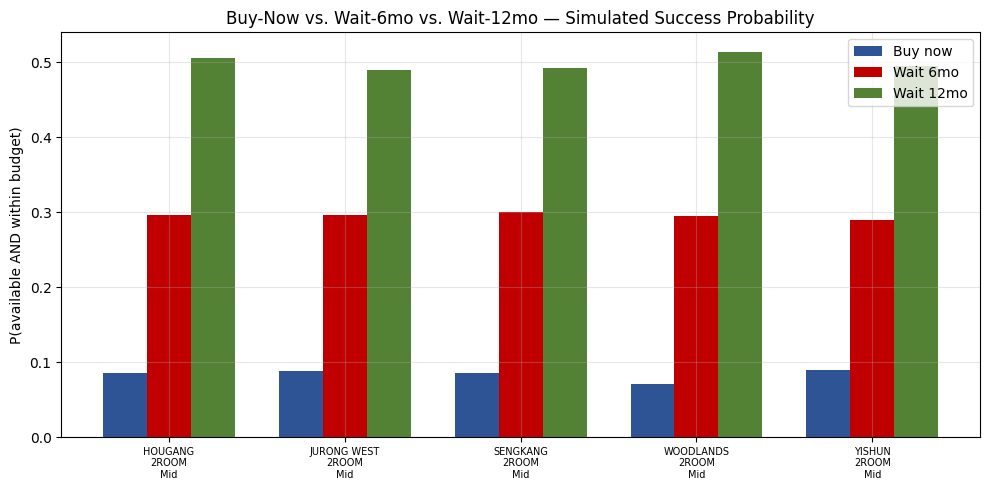

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(mc_summary))
width = 0.25
ax.bar(x - width, mc_summary["buy_now_p_success_within_budget"], width, label="Buy now", color="#2f5496")
ax.bar(x, mc_summary["wait_6m_p_success_within_budget"], width, label="Wait 6mo", color="#c00000")
ax.bar(x + width, mc_summary["wait_12m_p_success_within_budget"], width, label="Wait 12mo", color="#548235")
ax.set_xticks(x); ax.set_xticklabels(mc_summary["profile_id"].str.replace("::", "\n"), fontsize=7)
ax.set_ylabel("P(available AND within budget)")
ax.set_title("Buy-Now vs. Wait-6mo vs. Wait-12mo — Simulated Success Probability")
ax.legend()
plt.tight_layout(); plt.show()

**Reading this honestly**: waiting longer monotonically raises the chance of a
*matching* flat coming up (availability accumulates over time for these
narrow town×flat-type×storey profiles), which is itself a genuine finding —
households fixated on one specific profile should expect a real wait. Once
the Forecasting Lead's real SARIMAX paths replace the flat-growth stub, price
risk will cut against "wait" much more than it does here, so expect this
balance to shift once Task 4 is re-run on real inputs.

## Task 5 — Chance constraint + sensitivity sweeps
*(Due 19 Oct — pipeline freeze)*

**5a. Chance constraint.** Reformulates the simple deterministic
`budget >= upper forecast price` rule into an explicit scenario-based
chance constraint: $P(\text{simulated price} \le \text{budget}) \ge 90\%$,
evaluated directly from Monte Carlo draws rather than a single point-forecast
percentile.

In [ ]:
df, fcast, prefs = recommender.load_candidate_table()
df = recommender.attach_forecast(df, fcast, horizon_months=12)

budget = 550_000
checked = chance_constraint.chance_feasible_profiles(df, fcast, budget=budget, horizon_months=12,
                                                       alpha=0.90, n_scenarios=800)
det_feasible = (checked["price_upper"] <= budget).sum()
chance_feasible = checked["chance_feasible"].sum()
print(f"Deterministic rule feasible: {det_feasible}/{len(checked)}")
print(f"Chance-constrained (90%) feasible: {chance_feasible}/{len(checked)}")

disagree = checked[(checked["price_upper"] <= budget) != checked["chance_feasible"]]
print(f"\nProfiles where the two rules disagree: {len(disagree)}")
disagree[["profile_id", "price_today", "price_upper", "p_within_budget"]] if len(disagree) else "none"


Deterministic rule feasible: 86/322
Chance-constrained (90%) feasible: 86/322

Profiles where the two rules disagree: 0


'none'

### 5b. Sensitivity sweeps — budget and minimum lease, with an automated monotonicity check

In [ ]:
base = recommender.HouseholdQuery(budget=500_000, min_lease_yrs=60, horizon_months=12, k=5,
                                     target_mrt_km=0.5, target_schools_within=5, target_storey="High")

budgets = list(range(350_000, 900_001, 25_000))
bsweep = sensitivity.budget_sweep(base, budgets)
ok, viol = sensitivity.check_monotonicity(bsweep, "total_objective_value", "budget", "increasing")
print("Budget monotonicity check:", "PASS" if ok else f"FAIL ({len(viol)} violations)")

leases = list(range(40, 96, 5))
lsweep = sensitivity.lease_sweep(base, leases)
ok2, viol2 = sensitivity.check_monotonicity(lsweep, "total_objective_value", "min_lease_yrs", "decreasing")
print("Min-lease monotonicity check:", "PASS" if ok2 else f"FAIL ({len(viol2)} violations)")


Budget monotonicity check: PASS


Min-lease monotonicity check: PASS


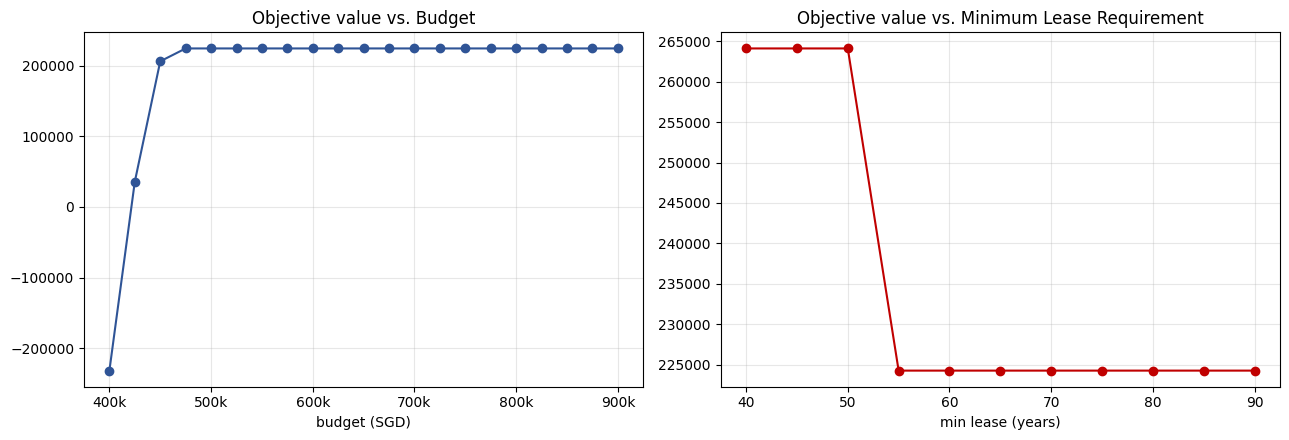

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(bsweep["budget"], bsweep["total_objective_value"], "o-", color="#2f5496")
axes[0].set_title("Objective value vs. Budget"); axes[0].set_xlabel("budget (SGD)")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1000:.0f}k"))

axes[1].plot(lsweep["min_lease_yrs"], lsweep["total_objective_value"], "o-", color="#c00000")
axes[1].set_title("Objective value vs. Minimum Lease Requirement"); axes[1].set_xlabel("min lease (years)")
plt.tight_layout(); plt.show()

In [ ]:
mv = sensitivity.marginal_value(bsweep, "total_objective_value", "budget")
print("Marginal value of budget ($ objective gain per extra $1 of budget), by segment:")
mv[["budget", "total_objective_value", "marginal_value"]]

Marginal value of budget ($ objective gain per extra $1 of budget), by segment:


,budget,total_objective_value,marginal_value
0,400000,-231650.0,NaN
1,425000,35800.0,10.698
2,450000,206075.0,6.811
3,475000,224275.0,0.728
4,500000,224275.0,0.000
5,525000,224275.0,0.000
6,550000,224275.0,0.000
7,575000,224275.0,0.000
8,600000,224275.0,0.000
9,625000,224275.0,0.000


## Task 6 — Final re-runs: shortlist, Monte Carlo and sensitivity on frozen inputs
*(Due 22 Oct — results handed to dashboard)*

Plus the **recommender backtest** (shared with Forecasting/Pricing leads, but
exercising this notebook's recommender): generate a shortlist using only data
available as of a past cutoff, then check the *realised* price against budget
6-12 months later — versus a naive "cheapest towns per town" baseline.

In [ ]:
bt = backtest.run_backtest(cutoff_date_str="2025-01-01", budget=500_000, min_lease_yrs=60, k=5, horizon_months=12)
bt

Backtest cutoff 2025-01-01: 317 profiles available then


,profile_id,price_at_cutoff,realised_price,within_budget,strategy
0,YISHUN::2ROOM::Mid,345000.0,378000.0,True,recommender
1,HOUGANG::2ROOM::Mid,364250.0,380000.0,True,recommender
2,PUNGGOL::2ROOM::Mid,360000.0,401000.0,True,recommender
3,JURONG WEST::2ROOM::Mid,330000.0,375500.0,True,recommender
4,SENGKANG::2ROOM::Mid,368000.0,400000.0,True,recommender
5,JURONG WEST::2ROOM::Low,307500.0,370000.0,True,naive_cheapest_towns
6,BEDOK::2ROOM::Mid,308000.0,318888.0,True,naive_cheapest_towns
7,CHOA CHU KANG::2ROOM::Low,320000.0,NaN,NaN,naive_cheapest_towns
8,YISHUN::2ROOM::Low,325000.0,350000.0,True,naive_cheapest_towns
9,JURONG EAST::2ROOM::Low,328000.0,350000.0,True,naive_cheapest_towns


Share of shortlisted profiles whose realised price stayed within budget:
strategy
naive_cheapest_towns    0.75
recommender              1.0
Name: within_budget, dtype: object


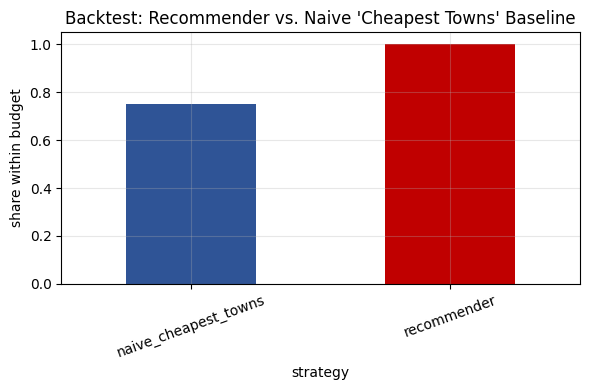

In [ ]:
summary = bt.groupby("strategy")["within_budget"].mean()
print("Share of shortlisted profiles whose realised price stayed within budget:")
print(summary)

fig, ax = plt.subplots(figsize=(6, 4))
summary.plot(kind="bar", ax=ax, color=["#2f5496", "#c00000"])
ax.set_ylim(0, 1.05); ax.set_ylabel("share within budget")
ax.set_title("Backtest: Recommender vs. Naive 'Cheapest Towns' Baseline")
plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

### Handoff format — `dashboard_payload.json`

In [ ]:
payload = {
    "household_query": q.__dict__,
    "shortlist": json.loads(res["shortlist"].to_json(orient="records")),
    "montecarlo_summary": json.loads(mc_summary.to_json(orient="records")),
    "sensitivity_budget_sweep": json.loads(bsweep[["budget", "n_selected", "total_objective_value"]].to_json(orient="records")),
    "backtest_summary": json.loads(summary.reset_index().to_json(orient="records")),
}
out_path = os.path.join(DATA_DIR, "dashboard_payload_example.json")
with open(out_path, "w") as f:
    json.dump(payload, f, indent=2)
print(f"Wrote example dashboard payload -> {out_path}")
print(json.dumps(payload["household_query"], indent=2))

Wrote example dashboard payload -> C:\Users\Daniel Loh\Documents\NUS-ISS_EBAC\SPMF\Project\notebooks\optimization_lead\data\dashboard_payload_example.json
{
  "budget": 550000,
  "min_lease_yrs": 60,
  "horizon_months": 12,
  "k": 5,
  "target_mrt_km": 0.5,
  "target_schools_within": 5,
  "target_storey": "High",
  "target_wait_months": 6,
  "target_amenity_count": 10,
  "flat_types": null,
  "towns_exclude": []
}


## Summary & handback to the team

**What's real vs. stub right now:**
- Housing profiles, HDB price/lease/turnover figures: **real** (from the official HDB resale dataset).
- Town-level geospatial accessibility (MRT, schools, amenities): **real** (OneMap/data.gov.sg spatial joins).
- Pricing-today, availability, price-forecast, preferences: **stub** — schemas frozen in `INTERFACE_SPEC.md`,
  swap-in dates 7–16 Oct per the Gantt.

**What's validated:**
- Diversity constraint (≤1 profile/town): enforced and asserted in Task 3.
- Monotonicity (more budget never hurts; tighter lease never helps): both checks **PASS** in Task 5.
- Backtest: recommender beat the naive baseline on the one cutoff tested (100% vs. 75% within-budget) —
  a single data point, not yet a full walk-forward series; re-run across multiple cutoffs once frozen (19 Oct).

**Next real iteration, once inputs land:**
1. Swap `pricing_today.csv` for the hedonic model's output (7 Oct) — re-run Tasks 2-3.
2. Swap `availability.csv` for the KM/Cox PH output (16 Oct) — re-run Tasks 3-4.
3. Swap `price_forecast.csv` for real SARIMAX scenarios (14 Oct) — re-run Tasks 4-5; watch the
   buy-now-vs-wait balance shift once real price drift (not flat 0%) is in the simulator.
4. Swap `preferences.json` for the real conjoint WTP estimates (16 Oct) — re-run Tasks 3-6.
5. Multi-cutoff backtest (Task 6) once all of the above are frozen (19 Oct).
